In [17]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

In [18]:
(x_train, y_train), (x_test, y_test) = ( tf.keras.datasets.mnist.load_data())
print("Training image:",x_train.shape)
print("Training label:",y_train.shape)
print("Testing image:", x_test.shape)
print("Testing label:", y_test.shape)

Training image: (60000, 28, 28)
Training label: (60000,)
Testing image: (10000, 28, 28)
Testing label: (10000,)


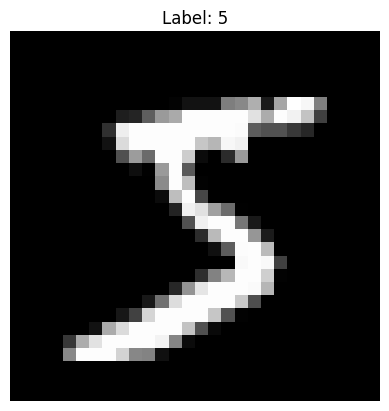

In [19]:
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

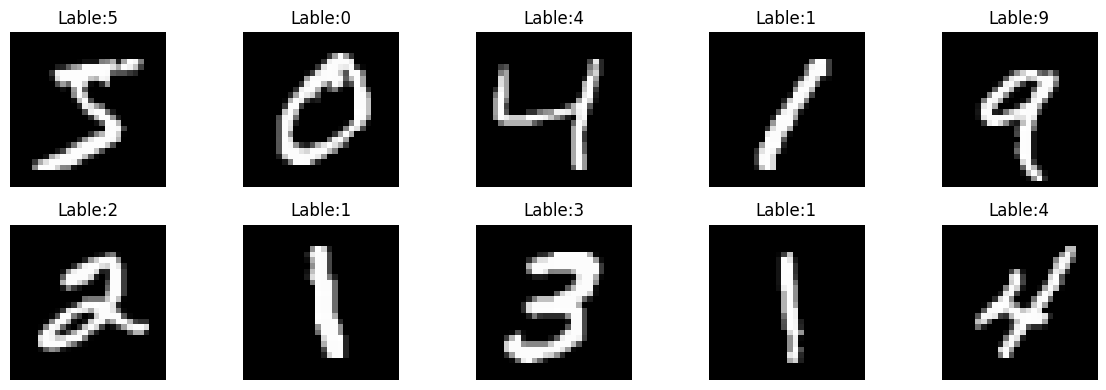

In [20]:
plt.figure(figsize=(12,4))
for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(x_train[i], cmap="gray")
  plt.title(f"Lable:{y_train[i]}")
  plt.axis("off")
plt.tight_layout()
plt.show()

In [21]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train = x_train[...,np.newaxis]
x_test = x_test[...,np.newaxis]
print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


In [22]:
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation="relu", input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

Epoch 1/5
217/844 ━━━━━━━━━━━━━━━━━━━━ 35s 57ms/step - accuracy: 0.7183 - loss: 0.9060

In [ ]:
index = 0
prediction = model.predict(x_test[index:index+1])
print("predicted digit:",np.argmax(prediction))
print("Actual digit:",y_test[index])
plt.imshow(x_test[index].reshape(28,28), cmap="gray")
plt.show()

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title("CNN Training Accuracy")
plt.legend()
plt.grid(True)
plt.show()